# kNN and Neural Network Models

*By Damien Wilson.*

A k-nearest-neighbors model (k chosen by cross-validation) and a small neural network predict continuous valence (regression) and the sad label (valence < 0.3, classification).
The inputs are the 141 numeric features in train_features.csv; test_features.csv is used for final scoring.
The setup, folds, metrics, and thresholds match tree_models.ipynb so the results can be compared directly.

## 1. Setup

Import the libraries and set the random seed and number of parallel CPU fits.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.neural_network import MLPRegressor, MLPClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import (KFold, StratifiedKFold, GridSearchCV,
                                     cross_validate, cross_val_predict)
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, precision_recall_curve,
                             average_precision_score)

warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.max_columns", None)
RANDOM_STATE = 42
SAD_CUTOFF = 0.3
N_JOBS = 2

Load the training features and targets. The text column track_genre is excluded because genre is already represented by the genre_* columns.

In [2]:
train_df = pd.read_csv("train_features.csv")

X = train_df.drop(columns=["valence", "sad", "track_genre"]).copy()
y = train_df["valence"]
y_sad = train_df["sad"]

print("X shape:", X.shape)
print(f"Share of sad songs: {y_sad.mean():.1%}")
X.head()

X shape: (63138, 141)
Share of sad songs: 31.0%


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,log_liveness,tempo,log_duration,mode,explicit,key_0,key_1,key_2,key_3,key_4,key_5,key_6,key_7,key_8,key_9,key_10,key_11,is_4_4,is_instrumental,is_slow,energy_sq,acousticness_sq,energy_x_acousticness,genre_acoustic,genre_afrobeat,genre_alt-rock,genre_alternative,genre_ambient,genre_anime,genre_black-metal,genre_bluegrass,genre_blues,genre_brazil,genre_breakbeat,genre_british,genre_cantopop,genre_chicago-house,genre_children,genre_chill,genre_classical,genre_club,genre_country,genre_dance,genre_dancehall,genre_death-metal,genre_deep-house,genre_detroit-techno,genre_disco,genre_disney,genre_drum-and-bass,genre_dub,genre_dubstep,genre_edm,genre_electro,genre_electronic,genre_emo,genre_folk,genre_forro,genre_french,genre_funk,genre_garage,genre_german,genre_gospel,genre_goth,genre_grindcore,genre_groove,genre_grunge,genre_guitar,genre_happy,genre_hard-rock,genre_hardcore,genre_hardstyle,genre_heavy-metal,genre_hip-hop,genre_honky-tonk,genre_house,genre_idm,genre_indian,genre_indie,genre_indie-pop,genre_industrial,genre_iranian,genre_j-dance,genre_j-idol,genre_j-pop,genre_j-rock,genre_jazz,genre_k-pop,genre_kids,genre_latin,genre_latino,genre_malay,genre_mandopop,genre_metal,genre_metalcore,genre_minimal-techno,genre_mpb,genre_new-age,genre_opera,genre_pagode,genre_party,genre_piano,genre_pop,genre_pop-film,genre_power-pop,genre_progressive-house,genre_psych-rock,genre_punk,genre_punk-rock,genre_r-n-b,genre_reggae,genre_reggaeton,genre_rock,genre_rock-n-roll,genre_rockabilly,genre_romance,genre_sad,genre_salsa,genre_samba,genre_sertanejo,genre_show-tunes,genre_singer-songwriter,genre_ska,genre_songwriter,genre_soul,genre_spanish,genre_study,genre_swedish,genre_synth-pop,genre_tango,genre_techno,genre_trance,genre_trip-hop,genre_turkish,genre_world-music
0,0.345,0.351,-7.844,0.0343,0.7130,0.000000,-2.434974,96.538,11.926888,1,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0.123201,0.508369,0.250263,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0.469,0.650,-9.220,0.0344,0.0450,0.001110,-1.465338,123.929,12.995075,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0.422500,0.002025,0.029250,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0.622,0.459,-15.283,0.0449,0.0813,0.111000,-2.244316,135.033,12.737116,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0.210681,0.006610,0.037317,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0.320,0.384,-10.710,0.0362,0.2960,0.000006,-2.519498,119.353,12.634603,1,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0.147456,0.087616,0.113664,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0.524,0.515,-7.478,0.0427,0.6740,0.000000,-2.263364,169.882,12.163410,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0.265225,0.454276,0.347110,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


Both models depend on distances or gradient steps, so features on large scales would dominate the rest. Every model below is a pipeline that standardizes the features inside each training fold, which keeps validation data from influencing the scaling.

## 2. Cross-validation

Create five shuffled folds for regression and five stratified folds for classification.

In [3]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

### Evaluation functions

Calculate regression RMSE, MAE, and R2 using five-fold CV. Classification uses out-of-fold probabilities to calculate F1, ROC-AUC, and accuracy.

In [4]:
reg_results = []
clf_results = []

def eval_regressor(name, model, notes=""):
    scores = cross_validate(model, X, y, cv=kf, n_jobs=N_JOBS, error_score="raise",
                            scoring={"rmse": "neg_root_mean_squared_error",
                                     "mae": "neg_mean_absolute_error", "r2": "r2"})
    row = {"model": name,
           "RMSE": -scores["test_rmse"].mean(), "RMSE_std": scores["test_rmse"].std(),
           "MAE": -scores["test_mae"].mean(), "R2": scores["test_r2"].mean(), "notes": notes}
    reg_results.append(row)
    print(f"{name}: RMSE {row['RMSE']:.4f} (+/- {row['RMSE_std']:.4f}), "
          f"MAE {row['MAE']:.4f}, R2 {row['R2']:.4f}")
    return row

def record_classifier(name, proba, threshold=0.5, notes=""):
    pred = (proba >= threshold).astype(int)
    row = {"model": name, "threshold": threshold,
           "F1": f1_score(y_sad, pred), "ROC_AUC": roc_auc_score(y_sad, proba),
           "accuracy": (pred == y_sad).mean(), "notes": notes}
    clf_results.append(row)
    print(f"{name}: F1 {row['F1']:.4f}, ROC-AUC {row['ROC_AUC']:.4f}, "
          f"accuracy {row['accuracy']:.4f}")
    return row

def eval_classifier(name, model, notes=""):
    proba = cross_val_predict(model, X, y_sad, cv=skf,
                             method="predict_proba", n_jobs=N_JOBS)[:, 1]
    record_classifier(name, proba, notes=notes)
    return proba

### Tuning tables and plots

Display candidate scores and plot one parameter at a time, holding the other parameters at their selected values. Each plot is a separate figure.

In [10]:
def show_search(search):
    print("Best parameters:", search.best_params_)
    results = pd.DataFrame(search.cv_results_)
    parameters = [c for c in results if c.startswith("param_")]
    score_cols = [c for c in ["mean_train_score", "mean_test_score", "std_test_score", "rank_test_score"] if c in results]
    table = results[parameters + score_cols].copy()
    if search.scoring == "neg_root_mean_squared_error":
        for c in ["mean_train_score", "mean_test_score"]:
            if c in table:
                table[c] *= -1
    display(table.rename(columns={"mean_train_score": "training_score",
                                  "mean_test_score": "validation_score",
                                  "std_test_score": "validation_std",
                                  "rank_test_score": "rank"}).sort_values("rank"))

def plot_search(search, parameters, title):
    for parameter in parameters:
        results = pd.DataFrame(search.cv_results_)
        for other, value in search.best_params_.items():
            if other != parameter:
                results = results[[p[other] == value for p in results["params"]]]
        sign = -1 if search.scoring == "neg_root_mean_squared_error" else 1
        positions = np.arange(len(results))
        labels = [str(p[parameter]) for p in results["params"]]
        plt.figure(figsize=(8, 5))
        if "mean_train_score" in results:
            plt.plot(positions, sign * results["mean_train_score"], "o-", label="training")
        plt.errorbar(positions, sign * results["mean_test_score"],
                     yerr=results["std_test_score"], fmt="o-", capsize=3, label="validation")
        plt.xticks(positions, labels)
        plt.xlabel(parameter)
        plt.ylabel("RMSE" if sign == -1 else "ROC-AUC")
        plt.title(f"{title}: {parameter}")
        plt.legend()
        plt.tight_layout()
        plt.show()

## 3. Initial models

Evaluate the mean-valence and always-not-sad baselines, then evaluate each model with its default settings. The initial kNN uses k = 5. The initial neural network has one hidden layer of 100 units with early stopping on a 10% validation split.

In [6]:
def make_knn(task):
    est = KNeighborsRegressor() if task == "reg" else KNeighborsClassifier()
    return Pipeline([("scale", StandardScaler()), ("knn", est)])

def make_mlp(task):
    kwargs = dict(early_stopping=True, n_iter_no_change=10, max_iter=300, random_state=RANDOM_STATE)
    est = MLPRegressor(**kwargs) if task == "reg" else MLPClassifier(**kwargs)
    return Pipeline([("scale", StandardScaler()), ("mlp", est)])

initial_reg = {"kNN": make_knn("reg"), "Neural network": make_mlp("reg")}
initial_clf = {"kNN": make_knn("clf"), "Neural network": make_mlp("clf")}

eval_regressor("Baseline: predict mean", DummyRegressor(strategy="mean"))
eval_classifier("Baseline: always 'not sad'", DummyClassifier(strategy="most_frequent"));

Baseline: predict mean: RMSE 0.2621 (+/- 0.0008), MAE 0.2240, R2 -0.0000
Baseline: always 'not sad': F1 0.0000, ROC-AUC 0.5000, accuracy 0.6902


In [7]:
for name, model in initial_reg.items():
    eval_regressor(f"{name} (initial)", model)
pd.DataFrame(reg_results).round(4)

kNN (initial): RMSE 0.2070 (+/- 0.0009), MAE 0.1645, R2 0.3763
Neural network (initial): RMSE 0.1780 (+/- 0.0011), MAE 0.1404, R2 0.5388


,model,RMSE,RMSE_std,MAE,R2,notes
0,Baseline: predict mean,0.2621,0.0008,0.2240,-0.0000,
1,kNN (initial),0.2070,0.0009,0.1645,0.3763,
2,Neural network (initial),0.1780,0.0011,0.1404,0.5388,


In [8]:
for name, model in initial_clf.items():
    eval_classifier(f"{name} (initial)", model)
pd.DataFrame(clf_results).round(4)

kNN (initial): F1 0.5822, ROC-AUC 0.7865, accuracy 0.7644
Neural network (initial): F1 0.6643, ROC-AUC 0.8662, accuracy 0.8076


,model,threshold,F1,ROC_AUC,accuracy,notes
0,Baseline: always 'not sad',0.5,0.0000,0.5000,0.6902,
1,kNN (initial),0.5,0.5822,0.7865,0.7644,
2,Neural network (initial),0.5,0.6643,0.8662,0.8076,


## 4. Regression tuning

Select parameters by the lowest mean CV RMSE.

### 4.1 kNN

Choose k by cross-validation. Small k fits the training data closely and is noisy; large k averages over many songs and smooths the prediction. Distance weighting is also compared with equal weighting.

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best parameters: {'knn__n_neighbors': 80, 'knn__weights': 'distance'}


,param_knn__n_neighbors,param_knn__weights,training_score,validation_score,validation_std,rank
7,80,distance,-0.000000,0.197618,0.000764,1
6,80,uniform,0.195920,0.198485,0.000775,2
5,40,distance,-0.000000,0.198866,0.000757,3
3,20,distance,-0.000000,0.199806,0.000812,4
9,160,distance,-0.000000,0.199922,0.000728,5
4,40,uniform,0.195402,0.200520,0.000741,6
1,10,distance,-0.000000,0.200709,0.000991,7
8,160,uniform,0.199587,0.200923,0.000729,8
2,20,uniform,0.191693,0.201976,0.000785,9
0,10,uniform,0.182423,0.202522,0.000992,10


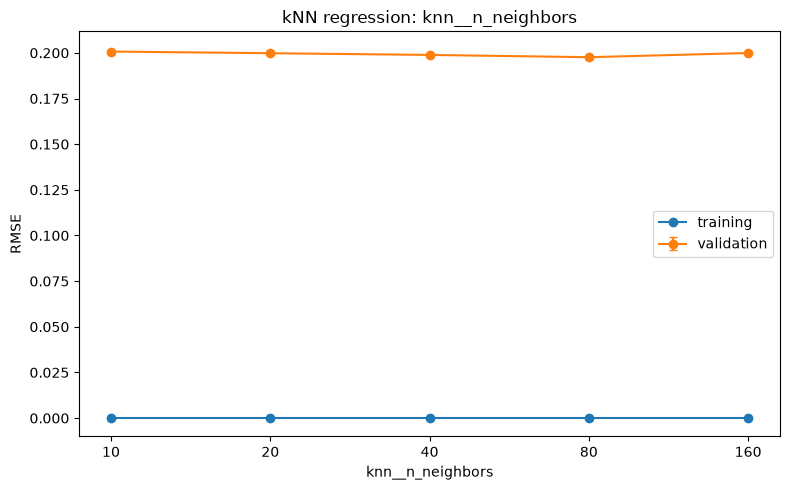

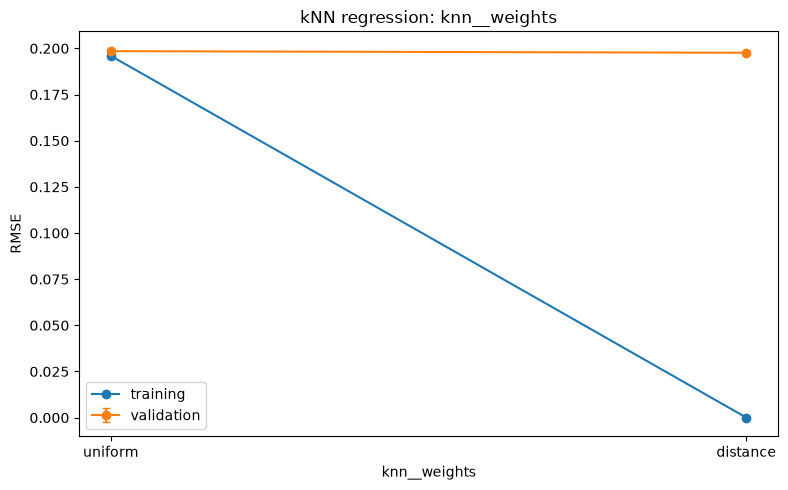

In [12]:
knn_params = {
    "knn__n_neighbors": [10, 20, 40, 80, 160],
    "knn__weights": ["uniform", "distance"],
}
knn_reg_grid = GridSearchCV(initial_reg["kNN"], knn_params,
                            cv=kf, scoring="neg_root_mean_squared_error",
                            return_train_score=True, error_score="raise", n_jobs=-1, verbose=1)
knn_reg_grid.fit(X, y)
show_search(knn_reg_grid)
plot_search(knn_reg_grid, list(knn_params), "kNN regression")

### 4.2 Neural network

Compare the hidden layer sizes and the L2 penalty (alpha). The network is kept small: one or two hidden layers with ReLU activations, the Adam optimizer, and early stopping.

Fitting 5 folds for each of 9 candidates, totalling 45 fits
Best parameters: {'mlp__alpha': 0.1, 'mlp__hidden_layer_sizes': (64, 32)}


,param_mlp__alpha,param_mlp__hidden_layer_sizes,training_score,validation_score,validation_std,rank
8,0.1000,"(64, 32)",0.167063,0.173646,0.001088,1
7,0.1000,"(64,)",0.167585,0.174911,0.000739,2
6,0.1000,"(16,)",0.170292,0.175219,0.001458,3
3,0.0100,"(16,)",0.170550,0.175320,0.001140,4
0,0.0001,"(16,)",0.171253,0.175882,0.000302,5
4,0.0100,"(64,)",0.164295,0.176097,0.000613,6
5,0.0100,"(64, 32)",0.160368,0.176774,0.001131,7
1,0.0001,"(64,)",0.165568,0.177114,0.000914,8
2,0.0001,"(64, 32)",0.161966,0.179056,0.001515,9


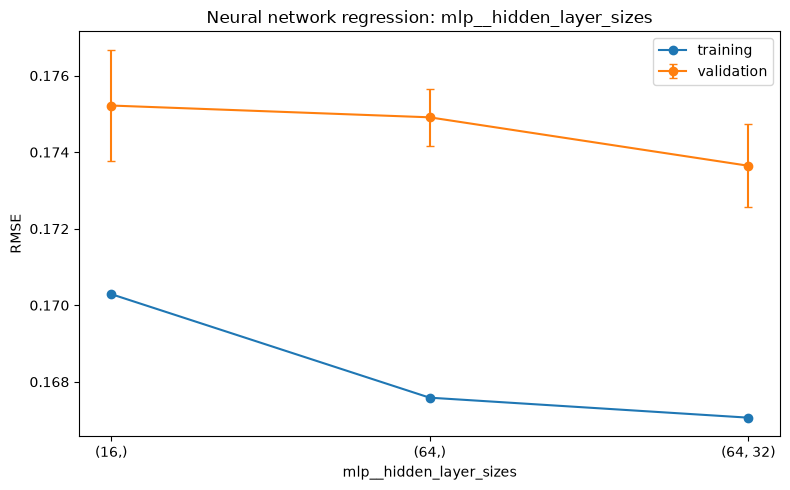

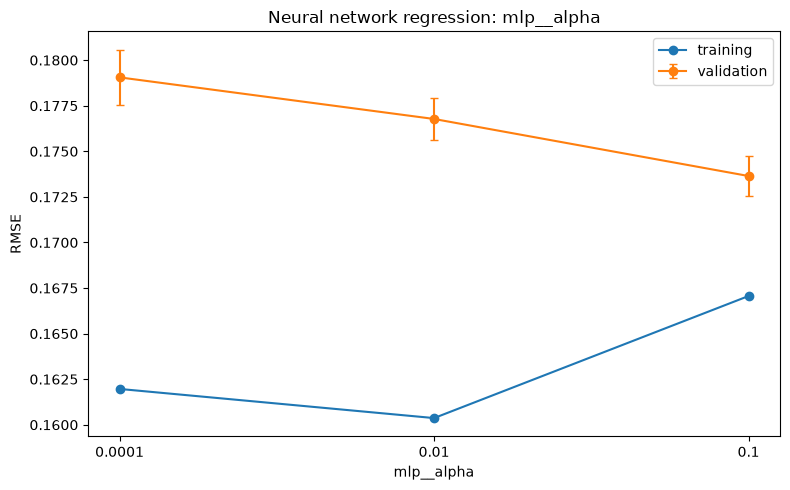

In [13]:
mlp_params = {
    "mlp__hidden_layer_sizes": [(16,), (64,), (64, 32)],
    "mlp__alpha": [1e-4, 1e-2, 1e-1],
}
mlp_reg_grid = GridSearchCV(initial_reg["Neural network"], mlp_params,
                            cv=kf, scoring="neg_root_mean_squared_error",
                            return_train_score=True, error_score="raise", n_jobs=N_JOBS, verbose=1)
mlp_reg_grid.fit(X, y)
show_search(mlp_reg_grid)
plot_search(mlp_reg_grid, list(mlp_params), "Neural network regression")

### 4.3 Tuned regression scores

Calculate RMSE, MAE, and R2 for each selected regressor and record its parameters.

In [14]:
tuned_reg = {
    "kNN (tuned)": knn_reg_grid.best_estimator_,
    "Neural network (tuned)": mlp_reg_grid.best_estimator_,
}
reg_notes = {
    "kNN (tuned)": str(knn_reg_grid.best_params_),
    "Neural network (tuned)": str(mlp_reg_grid.best_params_),
}
for name, model in tuned_reg.items():
    eval_regressor(name, model, notes=reg_notes[name])
pd.DataFrame(reg_results).round(4)

kNN (tuned): RMSE 0.1976 (+/- 0.0008), MAE 0.1606, R2 0.4317
Neural network (tuned): RMSE 0.1736 (+/- 0.0011), MAE 0.1374, R2 0.5612


,model,RMSE,RMSE_std,MAE,R2,notes
0,Baseline: predict mean,0.2621,0.0008,0.2240,-0.0000,
1,kNN (initial),0.2070,0.0009,0.1645,0.3763,
2,Neural network (initial),0.1780,0.0011,0.1404,0.5388,
3,kNN (tuned),0.1976,0.0008,0.1606,0.4317,"{'knn__n_neighbors': 80, 'knn__weights': 'dist..."
4,Neural network (tuned),0.1736,0.0011,0.1374,0.5612,"{'mlp__alpha': 0.1, 'mlp__hidden_layer_sizes':..."


## 5. Classification tuning

Select classifier parameters by the highest mean CV ROC-AUC.

### 5.1 kNN

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best parameters: {'knn__n_neighbors': 80, 'knn__weights': 'distance'}


,param_knn__n_neighbors,param_knn__weights,training_score,validation_score,validation_std,rank
7,80,distance,1.000000,0.831778,0.002035,1
6,80,uniform,0.840261,0.829770,0.002380,2
9,160,distance,1.000000,0.828197,0.002088,3
5,40,distance,1.000000,0.826397,0.001216,4
8,160,uniform,0.830929,0.825561,0.002448,5
4,40,uniform,0.843329,0.822842,0.001567,6
3,20,distance,1.000000,0.819176,0.002177,7
2,20,uniform,0.854007,0.814022,0.002487,8
1,10,distance,1.000000,0.810333,0.001820,9
0,10,uniform,0.876083,0.805468,0.001818,10


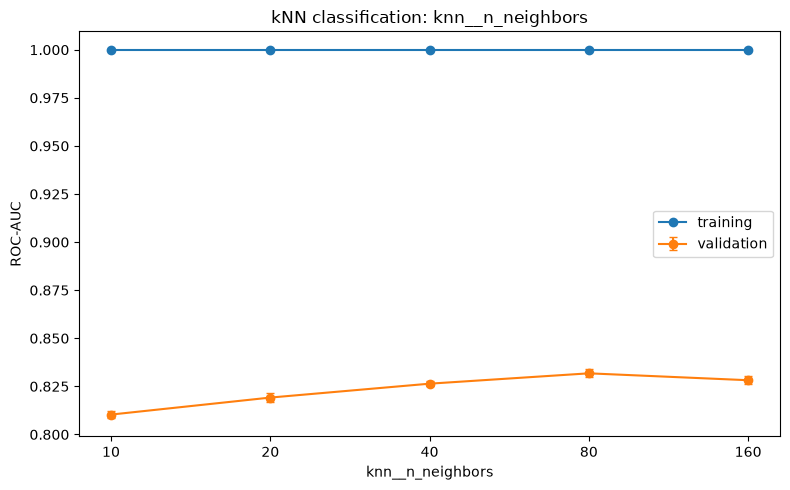

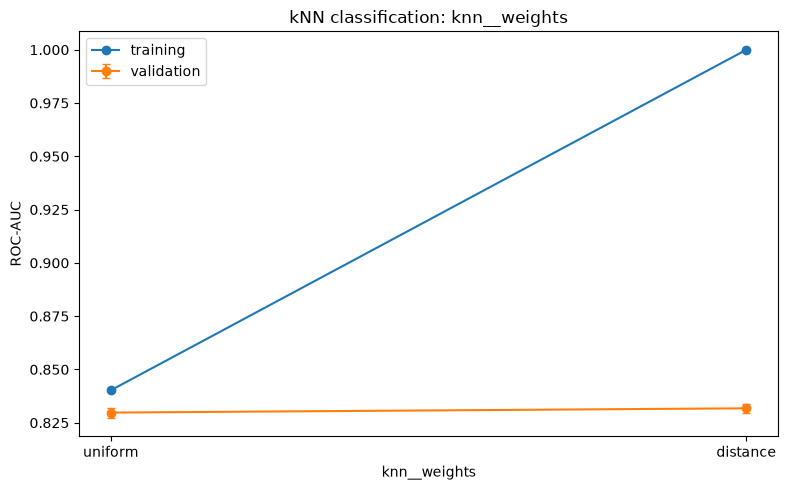

In [15]:
knn_clf_grid = GridSearchCV(initial_clf["kNN"], knn_params,
                            cv=skf, scoring="roc_auc", return_train_score=True, error_score="raise",
                            n_jobs=N_JOBS, verbose=1)
knn_clf_grid.fit(X, y_sad)
show_search(knn_clf_grid)
plot_search(knn_clf_grid, list(knn_params), "kNN classification")

### 5.2 Neural network

Fitting 5 folds for each of 9 candidates, totalling 45 fits
Best parameters: {'mlp__alpha': 0.1, 'mlp__hidden_layer_sizes': (16,)}


,param_mlp__alpha,param_mlp__hidden_layer_sizes,training_score,validation_score,validation_std,rank
6,0.1000,"(16,)",0.883592,0.870373,0.002656,1
7,0.1000,"(64,)",0.895681,0.869702,0.002218,2
4,0.0100,"(64,)",0.888667,0.869545,0.002786,3
1,0.0001,"(64,)",0.890069,0.869038,0.003790,4
0,0.0001,"(16,)",0.880463,0.868789,0.002429,5
3,0.0100,"(16,)",0.877561,0.868453,0.003560,6
2,0.0001,"(64, 32)",0.897602,0.868334,0.002158,7
8,0.1000,"(64, 32)",0.891430,0.868266,0.002067,8
5,0.0100,"(64, 32)",0.894869,0.867781,0.002370,9


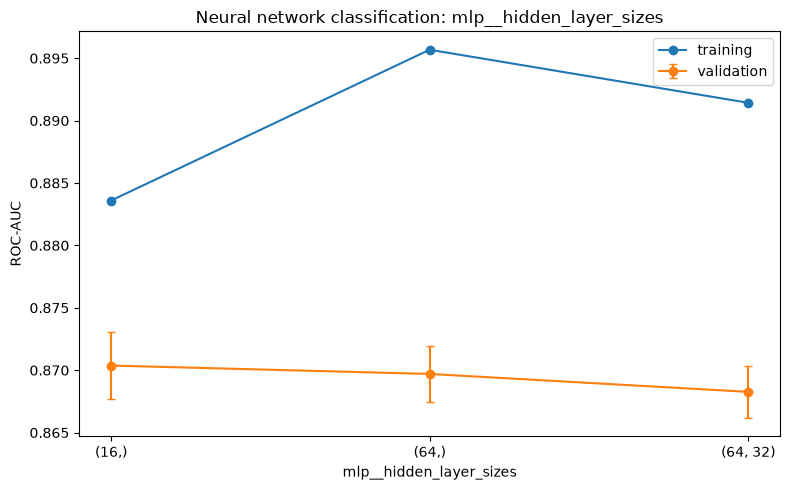

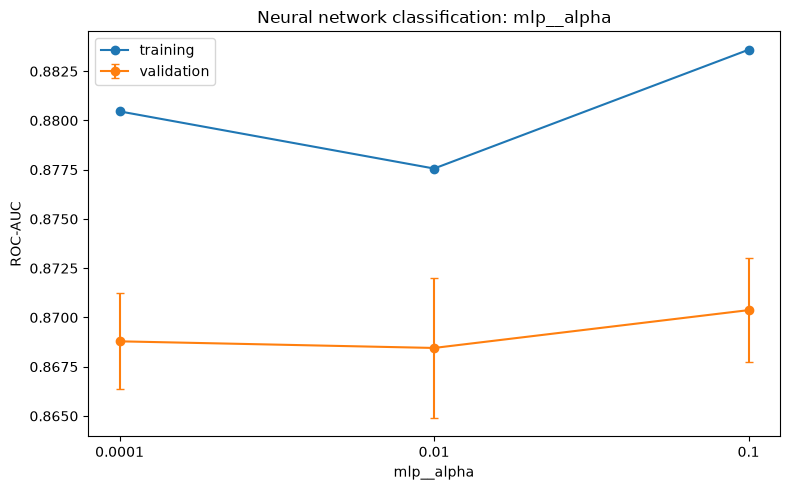

In [17]:
mlp_clf_grid = GridSearchCV(initial_clf["Neural network"], mlp_params,
                            cv=skf, scoring="roc_auc", return_train_score=True, error_score="raise",
                            n_jobs=N_JOBS, verbose=1)
mlp_clf_grid.fit(X, y_sad)
show_search(mlp_clf_grid)
plot_search(mlp_clf_grid, list(mlp_params), "Neural network classification")

### 5.3 Decision thresholds

For each classifier, generate out-of-fold probabilities and test thresholds from 0.05 to 0.95 in steps of 0.01. Select the threshold with the highest OOF F1 and also report F1 at 0.5.

kNN (tuned, threshold 0.32): F1 0.6505, ROC-AUC 0.8317, accuracy 0.7562
kNN (tuned, threshold 0.50): F1 0.5862, ROC-AUC 0.8317, accuracy 0.7841


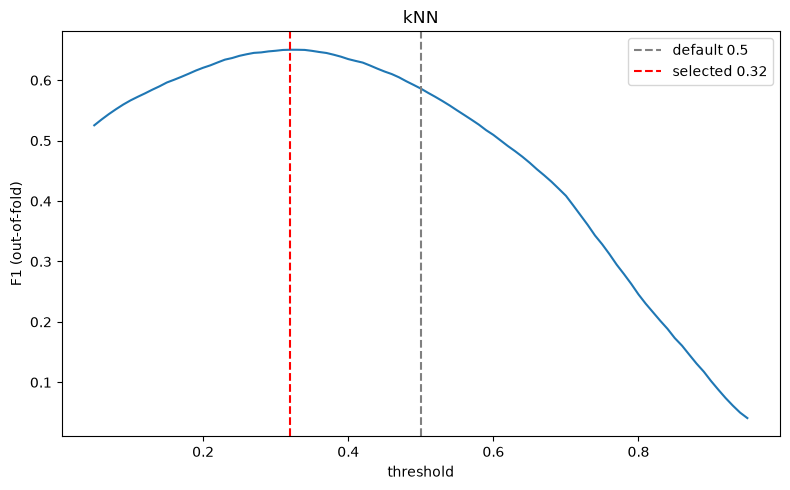

Neural network (tuned, threshold 0.35): F1 0.6967, ROC-AUC 0.8702, accuracy 0.7948
Neural network (tuned, threshold 0.50): F1 0.6698, ROC-AUC 0.8702, accuracy 0.8101


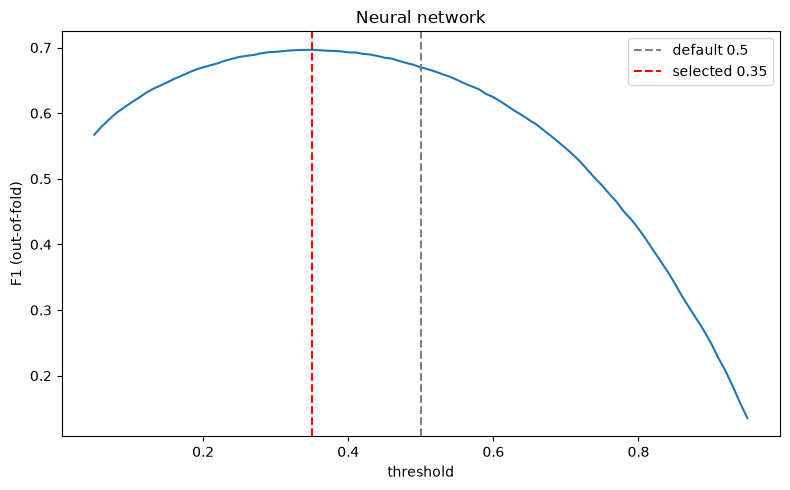

,model,threshold,F1,ROC_AUC,accuracy,notes
0,Baseline: always 'not sad',0.50,0.0000,0.5000,0.6902,
1,kNN (initial),0.50,0.5822,0.7865,0.7644,
2,Neural network (initial),0.50,0.6643,0.8662,0.8076,
3,"kNN (tuned, threshold 0.32)",0.32,0.6505,0.8317,0.7562,"{'knn__n_neighbors': 80, 'knn__weights': 'dist..."
4,"kNN (tuned, threshold 0.50)",0.50,0.5862,0.8317,0.7841,"{'knn__n_neighbors': 80, 'knn__weights': 'dist..."
5,"Neural network (tuned, threshold 0.35)",0.35,0.6967,0.8702,0.7948,"{'mlp__alpha': 0.1, 'mlp__hidden_layer_sizes':..."
6,"Neural network (tuned, threshold 0.50)",0.50,0.6698,0.8702,0.8101,"{'mlp__alpha': 0.1, 'mlp__hidden_layer_sizes':..."


In [18]:
tuned_clf = {
    "kNN": knn_clf_grid.best_estimator_,
    "Neural network": mlp_clf_grid.best_estimator_,
}
clf_notes = {
    "kNN": str(knn_clf_grid.best_params_),
    "Neural network": str(mlp_clf_grid.best_params_),
}
thresholds = np.arange(0.05, 0.96, 0.01)
best_thresholds = {}
clf_oof = {}

for name, model in tuned_clf.items():
    proba = cross_val_predict(model, X, y_sad, cv=skf, method="predict_proba", n_jobs=N_JOBS)[:, 1]
    clf_oof[name] = proba
    f1s = [f1_score(y_sad, (proba >= t).astype(int)) for t in thresholds]
    best_t = round(float(thresholds[int(np.argmax(f1s))]), 2)
    best_thresholds[name] = best_t
    for t in sorted({0.5, best_t}):
        record_classifier(f"{name} (tuned, threshold {t:.2f})", proba,
                          threshold=t, notes=clf_notes[name])
    plt.figure(figsize=(8, 5))
    plt.plot(thresholds, f1s)
    plt.axvline(0.5, color="gray", ls="--", label="default 0.5")
    plt.axvline(best_t, color="red", ls="--", label=f"selected {best_t:.2f}")
    plt.title(name)
    plt.xlabel("threshold")
    plt.ylabel("F1 (out-of-fold)")
    plt.legend()
    plt.tight_layout()
    plt.show()
pd.DataFrame(clf_results).round(4)

### 5.4 Classification diagnostics

Select the classifier with the highest OOF ROC-AUC and plot its confusion matrix, ROC curve, and precision-recall curve separately.

Selected classifier: Neural network | threshold: 0.35


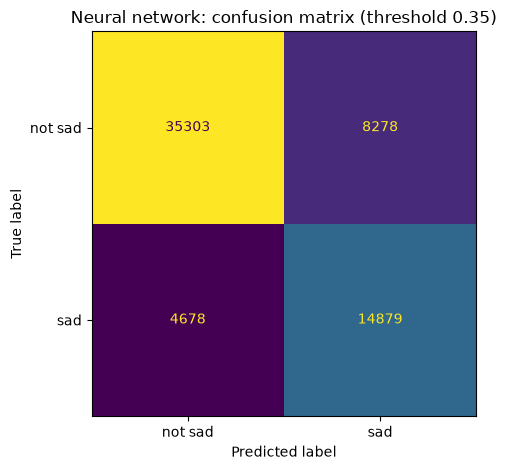

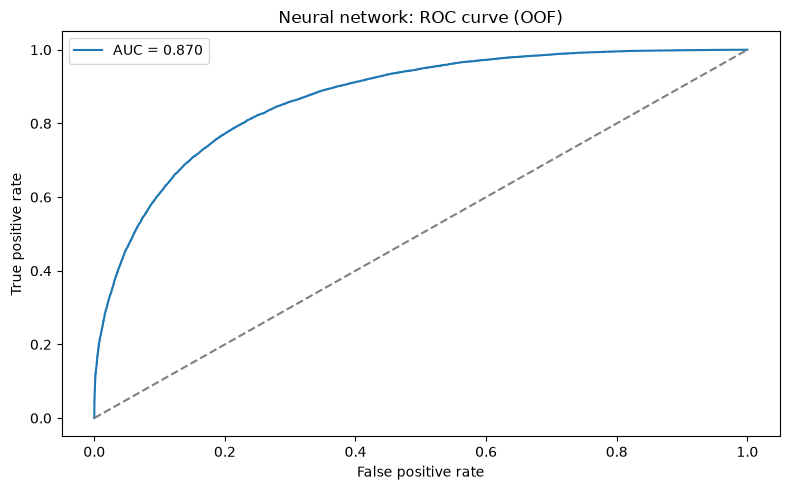

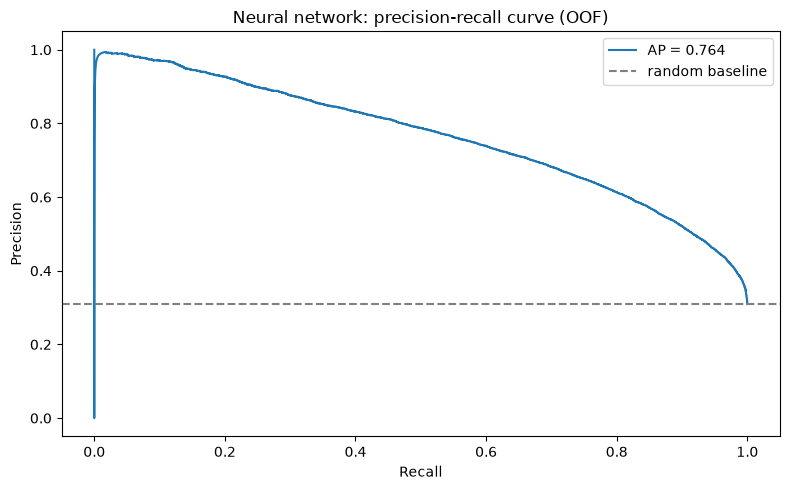

In [19]:
best_clf_name = max(clf_oof, key=lambda name: roc_auc_score(y_sad, clf_oof[name]))
oof_proba = clf_oof[best_clf_name]
best_t = best_thresholds[best_clf_name]
print("Selected classifier:", best_clf_name, "| threshold:", best_t)

ConfusionMatrixDisplay.from_predictions(y_sad, (oof_proba >= best_t).astype(int),
                                        display_labels=["not sad", "sad"], colorbar=False)
plt.title(f"{best_clf_name}: confusion matrix (threshold {best_t:.2f})")
plt.tight_layout()
plt.show()

fpr, tpr, _ = roc_curve(y_sad, oof_proba)
plt.figure(figsize=(8, 5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_sad, oof_proba):.3f}")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title(f"{best_clf_name}: ROC curve (OOF)")
plt.legend()
plt.tight_layout()
plt.show()

precision, recall, _ = precision_recall_curve(y_sad, oof_proba)
plt.figure(figsize=(8, 5))
plt.plot(recall, precision, label=f"AP = {average_precision_score(y_sad, oof_proba):.3f}")
plt.axhline(y_sad.mean(), color="gray", ls="--", label="random baseline")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"{best_clf_name}: precision-recall curve (OOF)")
plt.legend()
plt.tight_layout()
plt.show()

## 6. Model interpretation

### 6.1 Regression errors

Use OOF predictions from the selected regressor to plot predicted versus true valence and mean errors by valence range. Neither kNN nor a neural network has built-in feature importances, so this section looks at errors instead.

Selected regressor: Neural network (tuned)


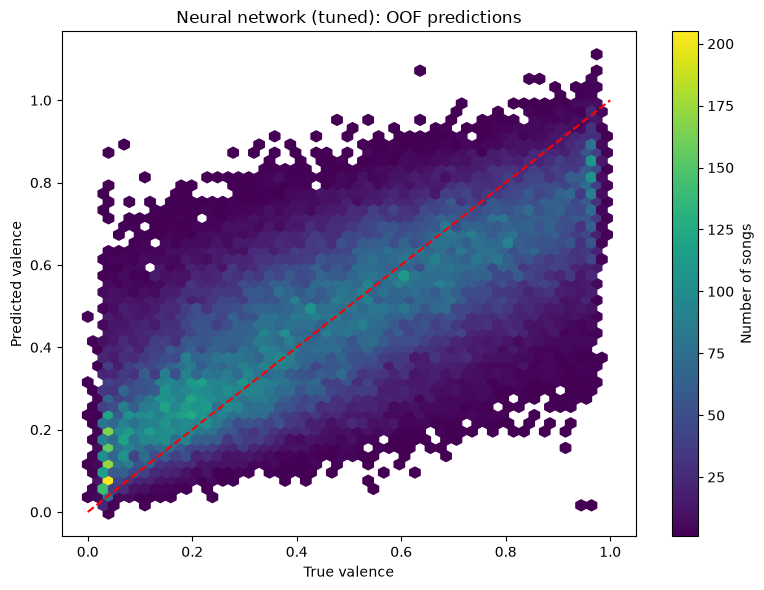

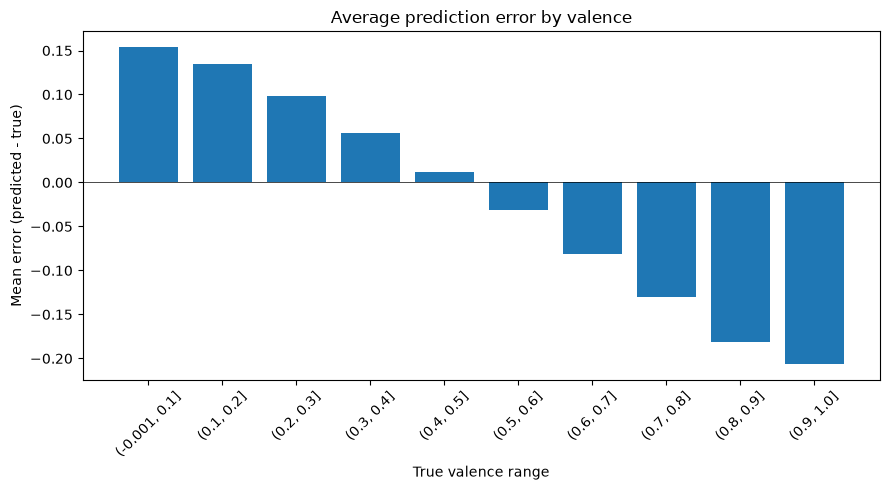

In [20]:
reg_cv = pd.DataFrame(reg_results).set_index("model")
best_reg_name = reg_cv.loc[list(tuned_reg), "RMSE"].idxmin()
best_reg = tuned_reg[best_reg_name]
print("Selected regressor:", best_reg_name)

oof_pred = cross_val_predict(best_reg, X, y, cv=kf, n_jobs=N_JOBS)
resid = oof_pred - y

plt.figure(figsize=(8, 6))
plt.hexbin(y, oof_pred, gridsize=50, cmap="viridis", mincnt=1)
plt.plot([0, 1], [0, 1], "--", color="red")
plt.xlabel("True valence")
plt.ylabel("Predicted valence")
plt.title(f"{best_reg_name}: OOF predictions")
plt.colorbar(label="Number of songs")
plt.tight_layout()
plt.show()

bins = pd.cut(y, np.arange(0, 1.01, 0.1), include_lowest=True)
by_bin = resid.groupby(bins, observed=True).mean()
plt.figure(figsize=(9, 5))
plt.bar([str(b) for b in by_bin.index], by_bin.values)
plt.axhline(0, color="black", lw=0.5)
plt.xlabel("True valence range")
plt.ylabel("Mean error (predicted - true)")
plt.title("Average prediction error by valence")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 6.2 Errors by energy

Compare prediction errors across low-, middle-, and high-energy songs with low valence, and songs with valence at least 0.3.

In [21]:
low = y < SAD_CUTOFF
groups = {
    "low valence, low energy (< 0.4) ~ sad/calm": low & (X["energy"] < 0.4),
    "low valence, high energy (> 0.7) ~ angry/intense": low & (X["energy"] > 0.7),
    "low valence, middle energy (0.4 to 0.7)": low & X["energy"].between(0.4, 0.7),
    "valence >= 0.3": ~low,
}
error_by_group = pd.DataFrame({
    name: {"songs": int(mask.sum()), "MAE": resid[mask].abs().mean(), "mean residual": resid[mask].mean()}
    for name, mask in groups.items()
}).T
display(error_by_group.round(3))

,songs,MAE,mean residual
"low valence, low energy (< 0.4) ~ sad/calm",6642.0,0.092,0.073
"low valence, high energy (> 0.7) ~ angry/intense",7347.0,0.162,0.152
"low valence, middle energy (0.4 to 0.7)",5568.0,0.163,0.155
valence >= 0.3,43581.0,0.137,-0.061


## 7. Final test scores

Fit each selected model on the full training set and calculate its test scores. Use the classification thresholds selected from training OOF predictions.

In [22]:
test_df = pd.read_csv("test_features.csv")
X_test = test_df.drop(columns=["valence", "sad", "track_genre"]).copy()
y_test = test_df["valence"]
y_test_sad = test_df["sad"]
print("Test set:", X_test.shape, f"| sad share {y_test_sad.mean():.1%}")

final_reg = {"Baseline: predict mean": DummyRegressor(strategy="mean"), **tuned_reg}
test_reg = []
for name, model in final_reg.items():
    pred = clone(model).fit(X, y).predict(X_test)
    test_reg.append({"model": name,
                     "test RMSE": np.sqrt(mean_squared_error(y_test, pred)),
                     "test MAE": mean_absolute_error(y_test, pred),
                     "test R2": r2_score(y_test, pred)})
pd.DataFrame(test_reg).round(4)

Test set: (15785, 141) | sad share 31.0%


,model,test RMSE,test MAE,test R2
0,Baseline: predict mean,0.2592,0.2213,-0.0002
1,kNN (tuned),0.1970,0.1601,0.4219
2,Neural network (tuned),0.1738,0.1370,0.5503


In [23]:
test_clf = []
base_clf = DummyClassifier(strategy="most_frequent").fit(X, y_sad)
base_pred = base_clf.predict(X_test)
test_clf.append({"model": "Baseline: always 'not sad'",
                 "test F1": f1_score(y_test_sad, base_pred), "test ROC-AUC": 0.5,
                 "test accuracy": (base_pred == y_test_sad).mean()})

for name, model in tuned_clf.items():
    proba = clone(model).fit(X, y_sad).predict_proba(X_test)[:, 1]
    for t in sorted({0.5, best_thresholds[name]}):
        pred = (proba >= t).astype(int)
        test_clf.append({"model": f"{name} (tuned, threshold {t:.2f})",
                         "test F1": f1_score(y_test_sad, pred),
                         "test ROC-AUC": roc_auc_score(y_test_sad, proba),
                         "test accuracy": (pred == y_test_sad).mean()})
pd.DataFrame(test_clf).round(4)

,model,test F1,test ROC-AUC,test accuracy
0,Baseline: always 'not sad',0.0000,0.5000,0.6903
1,"kNN (tuned, threshold 0.32)",0.6420,0.8245,0.7483
2,"kNN (tuned, threshold 0.50)",0.5723,0.8245,0.7766
3,"Neural network (tuned, threshold 0.35)",0.6904,0.8649,0.7898
4,"Neural network (tuned, threshold 0.50)",0.6601,0.8649,0.8042


## 8. Save results

Combine CV and final test scores and save the regression and classification CSV files. Initial models have CV scores only.

In [24]:
reg_table = pd.DataFrame(reg_results).merge(pd.DataFrame(test_reg), on="model", how="left",
                                            validate="one_to_one")
clf_table = pd.DataFrame(clf_results).merge(pd.DataFrame(test_clf), on="model", how="left",
                                            validate="one_to_one")
reg_table.to_csv("results_knn_nn_regression.csv", index=False)
clf_table.to_csv("results_knn_nn_classification.csv", index=False)
print("Saved results_knn_nn_regression.csv and results_knn_nn_classification.csv")
display(reg_table.round(4))
display(clf_table.round(4))

Saved results_knn_nn_regression.csv and results_knn_nn_classification.csv


,model,RMSE,RMSE_std,MAE,R2,notes,test RMSE,test MAE,test R2
0,Baseline: predict mean,0.2621,0.0008,0.2240,-0.0000,,0.2592,0.2213,-0.0002
1,kNN (initial),0.2070,0.0009,0.1645,0.3763,,NaN,NaN,NaN
2,Neural network (initial),0.1780,0.0011,0.1404,0.5388,,NaN,NaN,NaN
3,kNN (tuned),0.1976,0.0008,0.1606,0.4317,"{'knn__n_neighbors': 80, 'knn__weights': 'dist...",0.1970,0.1601,0.4219
4,Neural network (tuned),0.1736,0.0011,0.1374,0.5612,"{'mlp__alpha': 0.1, 'mlp__hidden_layer_sizes':...",0.1738,0.1370,0.5503


,model,threshold,F1,ROC_AUC,accuracy,notes,test F1,test ROC-AUC,test accuracy
0,Baseline: always 'not sad',0.50,0.0000,0.5000,0.6902,,0.0000,0.5000,0.6903
1,kNN (initial),0.50,0.5822,0.7865,0.7644,,NaN,NaN,NaN
2,Neural network (initial),0.50,0.6643,0.8662,0.8076,,NaN,NaN,NaN
3,"kNN (tuned, threshold 0.32)",0.32,0.6505,0.8317,0.7562,"{'knn__n_neighbors': 80, 'knn__weights': 'dist...",0.6420,0.8245,0.7483
4,"kNN (tuned, threshold 0.50)",0.50,0.5862,0.8317,0.7841,"{'knn__n_neighbors': 80, 'knn__weights': 'dist...",0.5723,0.8245,0.7766
5,"Neural network (tuned, threshold 0.35)",0.35,0.6967,0.8702,0.7948,"{'mlp__alpha': 0.1, 'mlp__hidden_layer_sizes':...",0.6904,0.8649,0.7898
6,"Neural network (tuned, threshold 0.50)",0.50,0.6698,0.8702,0.8101,"{'mlp__alpha': 0.1, 'mlp__hidden_layer_sizes':...",0.6601,0.8649,0.8042


### Summary

Print the CV-selected models' final test scores and the regression scores before and after tuning.

In [25]:
reg_selected = reg_table.set_index("model").loc[best_reg_name]
clf_selected_name = f"{best_clf_name} (tuned, threshold {best_t:.2f})"
clf_selected = clf_table.set_index("model").loc[clf_selected_name]
print(f"Selected regressor: {best_reg_name}")
print(f"Test RMSE {reg_selected['test RMSE']:.4f}, MAE {reg_selected['test MAE']:.4f}, "
      f"R2 {reg_selected['test R2']:.4f}")
print(f"Selected classifier: {best_clf_name}, threshold {best_t:.2f}")
print(f"Test F1 {clf_selected['test F1']:.4f}, ROC-AUC {clf_selected['test ROC-AUC']:.4f}")
for name in ["kNN", "Neural network"]:
    initial = reg_cv.loc[f"{name} (initial)", "RMSE"]
    tuned = reg_cv.loc[f"{name} (tuned)", "RMSE"]
    print(f"{name}: CV RMSE {initial:.4f} -> {tuned:.4f} (initial -> tuned)")

Selected regressor: Neural network (tuned)
Test RMSE 0.1738, MAE 0.1370, R2 0.5503
Selected classifier: Neural network, threshold 0.35
Test F1 0.6904, ROC-AUC 0.8649
kNN: CV RMSE 0.2070 -> 0.1976 (initial -> tuned)
Neural network: CV RMSE 0.1780 -> 0.1736 (initial -> tuned)
